# Global Geometric Transformation Modeling Data Augmentation Pipeline (Train/Test Split & Class Balancing)

### Executive Summary & Scientific Rationale
In clinical anthropometry and out-of-sample malnutrition classification (**ONC**, **MAM**, **SAM**), evaluating model generalization requires a strict separation between **Train** and **Test** sets before data augmentation. Augmenting before splitting risks data leakage across train and test folds.

This notebook executes a rigorous, multi-stratified **80% Train / 20% Test** split across the 6,203 original specimens, stratified simultaneously by:
1. **Clinical Class** (`ONC`, `MAM`, `SAM`)
2. **Age Group** ($\le 24$ months vs $> 24$ months)
3. **Gender** (`Female` vs `Male`)

Following split verification:
- **Test Set (20%, n = 1,240)**: Kept strictly untouched with raw original distributions (1,056 ONC, 141 MAM, 43 SAM).
- **Train Set (80%, n = 4,963)**: 4,223 ONC, 566 MAM, 174 SAM.
- **Geometric Data Augmentation**: Minority classes in the training set are augmented using class-specific empirical parameters to achieve **707 samples per class** (MAM: 566 original + 141 synthetic = 707; SAM: 174 original + 533 synthetic = 707).

---


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from scipy.stats import ks_2samp

# Set random seed for reproducibility
np.random.seed(42)

# File paths
out_dir_path = r"e:\ap-govt-EDA-model-tainning-testing\GM_out_of_sample_classification-main\GM_out_of_sample_classification-ap-govt\Data-Augmentation-by-Geometric Transformation Modeling\train-test-split-and -augmentation"
os.makedirs(out_dir_path, exist_ok=True)
input_csv = os.path.join(out_dir_path, "final_cleaned_dataset_full.csv")

df_full = pd.read_csv(input_csv)
print(f"[Data Loading] Master dataset loaded successfully: {df_full.shape[0]} rows, {df_full.shape[1]} columns.")


[Data Loading] Master dataset loaded successfully: 6203 rows, 103 columns.


## 1. Stratified 80/20 Train-Test Split (6,203 Originals)

The dataset is partitioned into an **80% Training Set (4,963 samples)** and a **20% Test Set (1,240 samples)**. Stratification preserves class balance, age group distribution ($\le 24$ vs $> 24$ months), and gender ratio (`Female` vs `Male`).


In [2]:
# Define age group binning
df_full['age_group'] = df_full['age_month'].apply(lambda x: '<=24' if x <= 24 else '>24')

# Target exact counts specified:
# Train (80%): 4,223 ONC, 566 MAM, 174 SAM (Total = 4,963)
# Test (20%): 1,056 ONC, 141 MAM, 43 SAM (Total = 1,240)
target_train_counts = {'onc': 4223, 'mam': 566, 'sam': 174}
target_test_counts  = {'onc': 1056, 'mam': 141, 'sam': 43}

train_indices = []
test_indices = []

for cls in ['onc', 'mam', 'sam']:
    cls_df = df_full[df_full['Class_Type'] == cls]
    n_train_target = target_train_counts[cls]
    
    # Group by age_group and gender for multi-variable stratification
    groups = cls_df.groupby(['age_group', 'gender'])
    
    strata_info = []
    for g_key, g_df in groups:
        prop = len(g_df) / len(cls_df)
        ideal_train = prop * n_train_target
        strata_info.append({
            'key': g_key,
            'df': g_df,
            'len': len(g_df),
            'ideal_train': ideal_train,
            'n_train': int(round(ideal_train))
        })
        
    # Adjust integer allocation to sum to n_train_target exactly
    cur_sum = sum(s['n_train'] for s in strata_info)
    diff = n_train_target - cur_sum
    if diff != 0:
        strata_info.sort(key=lambda s: s['ideal_train'] - s['n_train'], reverse=(diff > 0))
        for i in range(abs(diff)):
            strata_info[i]['n_train'] += (1 if diff > 0 else -1)
            
    for s in strata_info:
        g_df_shuffled = s['df'].sample(frac=1, random_state=42)
        tr = g_df_shuffled.iloc[:s['n_train']].index.tolist()
        te = g_df_shuffled.iloc[s['n_train']:].index.tolist()
        train_indices.extend(tr)
        test_indices.extend(te)

df_train_orig = df_full.loc[train_indices].copy().reset_index(drop=True)
df_test_orig  = df_full.loc[test_indices].copy().reset_index(drop=True)

tr_onc = (df_train_orig['Class_Type']=='onc').sum()
tr_mam = (df_train_orig['Class_Type']=='mam').sum()
tr_sam = (df_train_orig['Class_Type']=='sam').sum()

te_onc = (df_test_orig['Class_Type']=='onc').sum()
te_mam = (df_test_orig['Class_Type']=='mam').sum()
te_sam = (df_test_orig['Class_Type']=='sam').sum()

print("=========================================================================")
print("             ORIGINAL DATASET STRATIFIED TRAIN / TEST SPLIT              ")
print("=========================================================================")
print(f"Total Original Specimens: {len(df_full)}")
print(f"  - Train Set (80%): {len(df_train_orig)} samples -> ONC: {tr_onc}, MAM: {tr_mam}, SAM: {tr_sam}")
print(f"  - Test Set  (20%): {len(df_test_orig)} samples -> ONC: {te_onc}, MAM: {te_mam}, SAM: {te_sam}\n")

print("--- Train Set Subgroup Breakdown (Age x Gender) ---")
print(pd.crosstab(df_train_orig['Class_Type'], [df_train_orig['age_group'], df_train_orig['gender']]))
print("\n--- Test Set Subgroup Breakdown (Age x Gender) ---")
print(pd.crosstab(df_test_orig['Class_Type'], [df_test_orig['age_group'], df_test_orig['gender']]))


             ORIGINAL DATASET STRATIFIED TRAIN / TEST SPLIT              
Total Original Specimens: 6203
  - Train Set (80%): 4963 samples -> ONC: 4223, MAM: 566, SAM: 174
  - Test Set  (20%): 1240 samples -> ONC: 1056, MAM: 141, SAM: 43

--- Train Set Subgroup Breakdown (Age x Gender) ---
age_group    <=24         >24      
gender     Female Male Female  Male
Class_Type                         
mam            30   76    232   228
onc           554  482   1625  1562
sam             8   38     38    90

--- Test Set Subgroup Breakdown (Age x Gender) ---
age_group    <=24         >24     
gender     Female Male Female Male
Class_Type                        
mam             7   19     58   57
onc           139  121    406  390
sam             2   10      9   22


## 2. Global Data Augmentation Engine with Class-Specific Empirical Parameters

The geometric transformation augmentation engine models physical variation (scaling $\beta$, rotation $\theta$, translation $\gamma_x, \gamma_y$, and digitization noise $\sigma$) using empirical parameters derived for each clinical class:

- **SAM (`class_type='sam'`)**:
  - Scale: $\beta \sim U(0.70, 1.22)$
  - Rotation: $\theta \sim U(-7.0^\circ, +6.4^\circ)$
  - Translation: $\gamma_x \in [-5.05, +3.85]$, $\gamma_y \in [-1.83, +2.39]$
  - Landmark Noise: $\sigma = 0.507$ mm

- **MAM (`class_type='mam'`)**:
  - Scale: $\beta \sim U(0.72, 1.22)$
  - Rotation: $\theta \sim U(-7.0^\circ, +6.4^\circ)$
  - Translation: $\gamma_x \in [-4.85, +3.72]$, $\gamma_y \in [-2.33, +1.99]$
  - Landmark Noise: $\sigma = 0.454$ mm

- **ONC (`class_type='onc'`)**:
  - Scale: $\beta \sim U(0.70, 1.22)$
  - Rotation: $\theta \sim U(-7.0^\circ, +6.4^\circ)$
  - Translation: $\gamma_x \in [-4.85, +3.82]$, $\gamma_y \in [-2.09, +2.14]$
  - Landmark Noise: $\sigma = 0.480$ mm


In [3]:
landmark_ids = [int(c.replace('X', '')) for c in df_full.columns if c.startswith('X') and c[1:].isdigit()]
K = len(landmark_ids)
id_to_idx = {lid: idx for idx, lid in enumerate(landmark_ids)}

gpa_x_cols = [f'GPA_X{lid}' for lid in landmark_ids]
gpa_y_cols = [f'GPA_Y{lid}' for lid in landmark_ids]

EMPIRICAL_PARAMS = {
    'sam': {
        'scale_min': 0.70, 'scale_max': 1.22,
        'rot_min_deg': -7.0, 'rot_max_deg': 6.4,
        'trans_x_min': -5.05, 'trans_x_max': 3.85,
        'trans_y_min': -1.83, 'trans_y_max': 2.39,
        'noise_scale': 0.507
    },
    'mam': {
        'scale_min': 0.72, 'scale_max': 1.22,
        'rot_min_deg': -7.0, 'rot_max_deg': 6.4,
        'trans_x_min': -4.85, 'trans_x_max': 3.72,
        'trans_y_min': -2.33, 'trans_y_max': 1.99,
        'noise_scale': 0.454
    },
    'onc': {
        'scale_min': 0.70, 'scale_max': 1.22,
        'rot_min_deg': -7.0, 'rot_max_deg': 6.4,
        'trans_x_min': -4.85, 'trans_x_max': 3.82,
        'trans_y_min': -2.09, 'trans_y_max': 2.14,
        'noise_scale': 0.480
    }
}

def generate_synthetic_geometric_augmentation(df_source, target_class, num_to_generate, seed=42):
    np.random.seed(seed)
    target_cls = str(target_class).lower()
    if target_cls not in EMPIRICAL_PARAMS:
        raise ValueError(f"Unknown target_class '{target_class}'. Supported: {list(EMPIRICAL_PARAMS.keys())}")
        
    params = EMPIRICAL_PARAMS[target_cls]
    cls_df = df_source[df_source['Class_Type'] == target_cls].reset_index(drop=True)
    N_cls = len(cls_df)
    
    if N_cls == 0:
        raise ValueError(f"Target class '{target_class}' not found in df_source!")
        
    cls_raw_shapes = np.zeros((N_cls, K, 2))
    for i in range(N_cls):
        for lid_idx, lid in enumerate(landmark_ids):
            cls_raw_shapes[i, lid_idx, 0] = cls_df.iloc[i][f'X{lid}']
            cls_raw_shapes[i, lid_idx, 1] = cls_df.iloc[i][f'Y{lid}']
            
    synth_rows = []
    synth_raw_shapes = np.zeros((num_to_generate, K, 2))
    
    for syn_i in range(num_to_generate):
        parent_idx = np.random.randint(0, N_cls)
        parent_row = cls_df.iloc[parent_idx]
        base_shape = cls_raw_shapes[parent_idx].copy()
        
        # 1. Landmark Gaussian digitization noise
        noise_x = np.random.normal(0, params['noise_scale'], size=K)
        noise_y = np.random.normal(0, params['noise_scale'], size=K)
        noisy_shape = base_shape + np.column_stack([noise_x, noise_y])
        
        # 2. Empirical 2D Rotation
        theta_deg = np.random.uniform(params['rot_min_deg'], params['rot_max_deg'])
        theta = np.radians(theta_deg)
        rot_matrix = np.array([[np.cos(theta), -np.sin(theta)], 
                               [np.sin(theta),  np.cos(theta)]])
        rotated_shape = noisy_shape @ rot_matrix
        
        # 3. Empirical Scaling
        beta = np.random.uniform(params['scale_min'], params['scale_max'])
        scaled_shape = rotated_shape * beta
        
        # 4. Empirical Translation
        tx = np.random.uniform(params['trans_x_min'], params['trans_x_max'])
        ty = np.random.uniform(params['trans_y_min'], params['trans_y_max'])
        augmented_shape = scaled_shape + np.array([tx, ty])
        
        synth_raw_shapes[syn_i] = augmented_shape
        
        row_dict = parent_row.to_dict()
        row_dict['File_Name'] = f"SYNTH_{target_cls.upper()}_GEO_{syn_i+1:04d}.png"
        row_dict['Individual'] = f"SYNTH_{target_cls.upper()}_{syn_i+1:04d}"
        row_dict['Class_Type'] = target_cls
        for lid_idx, lid in enumerate(landmark_ids):
            row_dict[f'X{lid}'] = augmented_shape[lid_idx, 0]
            row_dict[f'Y{lid}'] = augmented_shape[lid_idx, 1]
            
        synth_rows.append(row_dict)
        
    df_synth_raw = pd.DataFrame(synth_rows)
    
    # GPA superimposition & horizontal alignment
    synth_centroids = np.mean(synth_raw_shapes, axis=1, keepdims=True)
    synth_centered = synth_raw_shapes - synth_centroids
    synth_cs = np.linalg.norm(synth_centered, axis=(1, 2))
    synth_scaled = synth_centered / synth_cs[:, None, None]
    
    ref_raw_shapes = np.zeros((len(df_source), K, 2))
    for i in range(len(df_source)):
        for lid_idx, lid in enumerate(landmark_ids):
            ref_raw_shapes[i, lid_idx, 0] = df_source.iloc[i][f'X{lid}']
            ref_raw_shapes[i, lid_idx, 1] = df_source.iloc[i][f'Y{lid}']
            
    ref_centered = ref_raw_shapes - np.mean(ref_raw_shapes, axis=1, keepdims=True)
    ref_scaled = ref_centered / np.linalg.norm(ref_centered, axis=(1, 2))[:, None, None]
    
    pop_mean_shape = np.mean(ref_scaled, axis=0)
    pop_mean_shape /= np.linalg.norm(pop_mean_shape)
    
    synth_gpa_aligned = np.zeros_like(synth_scaled)
    for i in range(num_to_generate):
        H = synth_scaled[i].T @ pop_mean_shape
        U, S, Vt = np.linalg.svd(H)
        R = U @ Vt
        if np.linalg.det(R) < 0:
            Vt[-1, :] *= -1
            R = U @ Vt
        synth_gpa_aligned[i] = synth_scaled[i] @ R
        
    sh_i = id_to_idx[1]
    wr_i = id_to_idx[20]
    vec = pop_mean_shape[wr_i] - pop_mean_shape[sh_i]
    theta_horiz = np.arctan2(vec[1], vec[0])
    R_horiz = np.array([[np.cos(-theta_horiz), -np.sin(-theta_horiz)], 
                        [np.sin(-theta_horiz),  np.cos(-theta_horiz)]])
                        
    synth_gpa_horiz = np.zeros_like(synth_gpa_aligned)
    for i in range(num_to_generate):
        synth_gpa_horiz[i] = synth_gpa_aligned[i] @ R_horiz
        
    df_synth_raw['Centroid_Size'] = synth_cs
    for lid_idx, lid in enumerate(landmark_ids):
        df_synth_raw[f'GPA_X{lid}'] = synth_gpa_horiz[:, lid_idx, 0]
        df_synth_raw[f'GPA_Y{lid}'] = synth_gpa_horiz[:, lid_idx, 1]
        
    return df_synth_raw, synth_raw_shapes, synth_gpa_horiz

print("Global Geometric Augmentation Engine defined successfully with SAM, MAM, and ONC empirical parameter profiles.")


Global Geometric Augmentation Engine defined successfully with SAM, MAM, and ONC empirical parameter profiles.


## 3. Training Set Data Augmentation (Class Balancing to 707 Samples per Minority Class)

Using `df_train_orig` as the source cohort:
- **SAM Augmentation**: Generate **533 synthetic SAM samples** (174 original + 533 synthetic = 707 SAM samples).
- **MAM Augmentation**: Generate **141 synthetic MAM samples** (566 original + 141 synthetic = 707 MAM samples).
- **ONC Baseline**: Retain 4,223 original ONC samples (with option for 707 sampled ONC baseline).


In [4]:
# Augment SAM in Train set (174 orig -> 707 total: generate 533 synthetic SAM)
df_synth_sam, synth_raw_sam, synth_gpa_sam = generate_synthetic_geometric_augmentation(
    df_source=df_train_orig, target_class='sam', num_to_generate=533, seed=101
)
print(f"[Augmentation] Generated {len(df_synth_sam)} synthetic SAM specimens (Train SAM total = 707).")

# Augment MAM in Train set (566 orig -> 707 total: generate 141 synthetic MAM)
df_synth_mam, synth_raw_mam, synth_gpa_mam = generate_synthetic_geometric_augmentation(
    df_source=df_train_orig, target_class='mam', num_to_generate=141, seed=202
)
print(f"[Augmentation] Generated {len(df_synth_mam)} synthetic MAM specimens (Train MAM total = 707).")

# Fit PCA on Train Original GPA coordinates and project original and synthetic specimens
gpa_all_cols = gpa_x_cols + gpa_y_cols
orig_train_flat = df_train_orig[gpa_all_cols].values
pca_model = PCA(n_components=10)
pca_model.fit(orig_train_flat)

# Transform train original
pca_tr = pca_model.transform(orig_train_flat)
for pc_i in range(10):
    df_train_orig[f'PC{pc_i+1}'] = pca_tr[:, pc_i]

# Transform test original
orig_test_flat = df_test_orig[gpa_all_cols].values
pca_te = pca_model.transform(orig_test_flat)
for pc_i in range(10):
    df_test_orig[f'PC{pc_i+1}'] = pca_te[:, pc_i]

# Transform synthetic SAM and MAM
for df_s in [df_synth_sam, df_synth_mam]:
    s_flat = df_s[gpa_all_cols].values
    pca_s = pca_model.transform(s_flat)
    for pc_i in range(10):
        df_s[f'PC{pc_i+1}'] = pca_s[:, pc_i]

# Construct Main Training Set (ONC=4223, MAM=707, SAM=707)
df_train_augmented = pd.concat([df_train_orig, df_synth_sam, df_synth_mam], ignore_index=True)

# Construct 1:1:1 Balanced Training Set (ONC=707, MAM=707, SAM=707)
df_onc_707 = df_train_orig[df_train_orig['Class_Type'] == 'onc'].sample(n=707, random_state=42).reset_index(drop=True)
df_mam_707 = df_train_augmented[df_train_augmented['Class_Type'] == 'mam'].reset_index(drop=True)
df_sam_707 = df_train_augmented[df_train_augmented['Class_Type'] == 'sam'].reset_index(drop=True)
df_train_1to1to1 = pd.concat([df_onc_707, df_mam_707, df_sam_707], ignore_index=True)

print("\n--- Final Training Set Class Breakdown (ONC=4223, MAM=707, SAM=707) ---")
print(df_train_augmented['Class_Type'].value_counts())

print("\n--- 1:1:1 Balanced Training Set Class Breakdown (ONC=707, MAM=707, SAM=707) ---")
print(df_train_1to1to1['Class_Type'].value_counts())

print("\n--- Untouched Test Set Class Breakdown (ONC=1056, MAM=141, SAM=43) ---")
print(df_test_orig['Class_Type'].value_counts())


[Augmentation] Generated 533 synthetic SAM specimens (Train SAM total = 707).
[Augmentation] Generated 141 synthetic MAM specimens (Train MAM total = 707).

--- Final Training Set Class Breakdown (ONC=4223, MAM=707, SAM=707) ---
Class_Type
onc    4223
mam     707
sam     707
Name: count, dtype: int64

--- 1:1:1 Balanced Training Set Class Breakdown (ONC=707, MAM=707, SAM=707) ---
Class_Type
onc    707
mam    707
sam    707
Name: count, dtype: int64

--- Untouched Test Set Class Breakdown (ONC=1056, MAM=141, SAM=43) ---
Class_Type
onc    1056
mam     141
sam      43
Name: count, dtype: int64


## 4. Morphospace Visualization & Kolmogorov-Smirnov Statistical Distribution Validation

We visualize the morphospace (PC1 vs PC2) and Procrustes Consensus Mean shapes, followed by two-sample Kolmogorov-Smirnov (KS) tests to confirm distribution alignment between original and synthetic training samples.


          KOLMOGOROV-SMIRNOV FEATURE DISTRIBUTION ALIGNMENT              
SAM PC1 (Original Train vs Synthetic Train): KS Stat = 0.0429, p-value = 0.9583
MAM PC1 (Original Train vs Synthetic Train): KS Stat = 0.0530, p-value = 0.8882


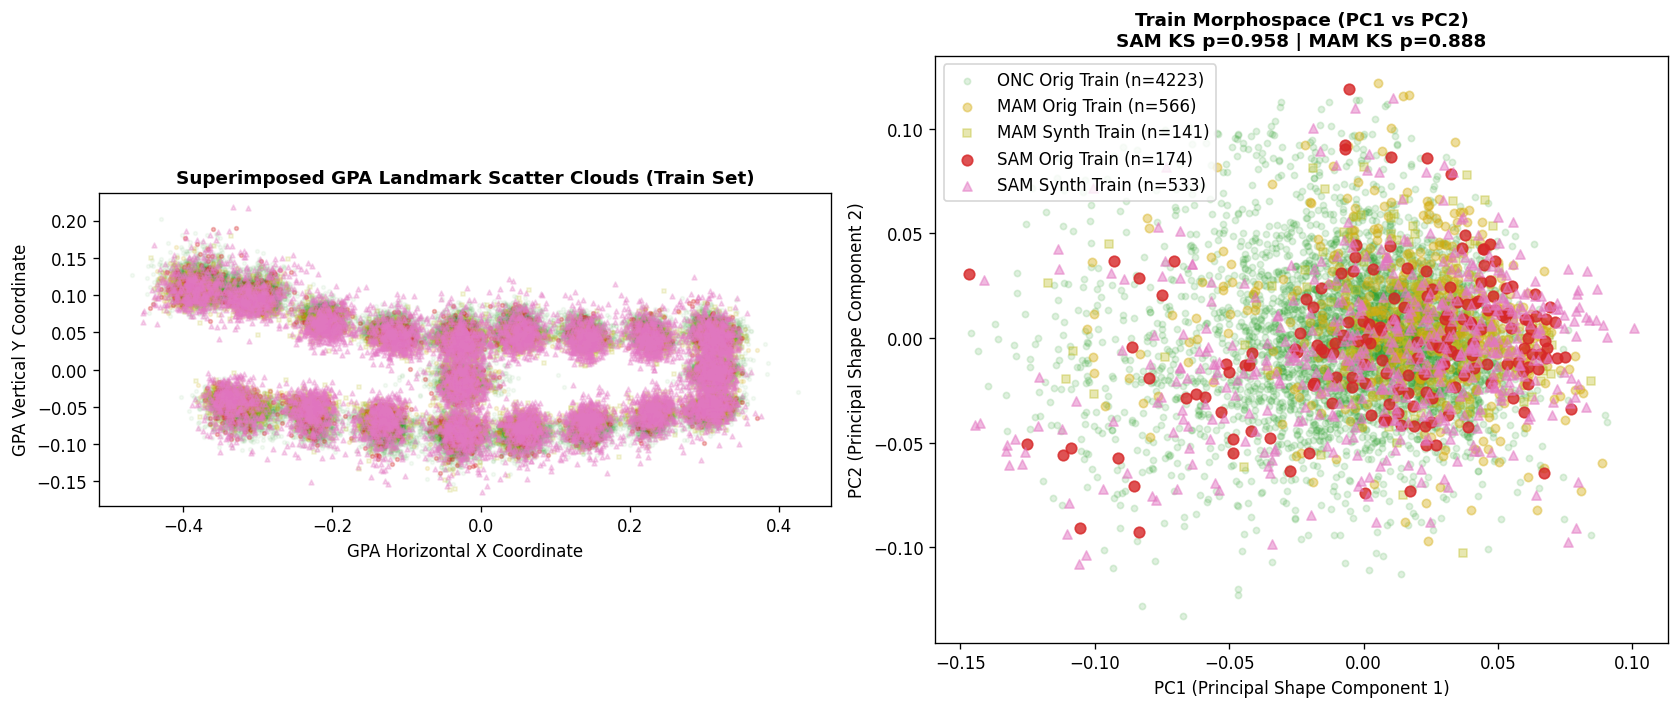

In [5]:
# 1. Scatter Cloud Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Subplot 1: Raw Landmark Scatter
ax = axes[0]
for i in range(len(df_train_orig)):
    cls = df_train_orig.iloc[i]['Class_Type']
    color = '#2ca02c' if cls == 'onc' else ('#d4ac0d' if cls == 'mam' else '#d62728')
    alpha = 0.05 if cls == 'onc' else (0.15 if cls == 'mam' else 0.3)
    ax.scatter(df_train_orig.iloc[i][gpa_x_cols], df_train_orig.iloc[i][gpa_y_cols], color=color, alpha=alpha, s=5)

for i in range(len(df_synth_mam)):
    ax.scatter(df_synth_mam.iloc[i][gpa_x_cols], df_synth_mam.iloc[i][gpa_y_cols], color='#bcbd22', alpha=0.15, s=5, marker='s')

for i in range(len(df_synth_sam)):
    ax.scatter(df_synth_sam.iloc[i][gpa_x_cols], df_synth_sam.iloc[i][gpa_y_cols], color='#e377c2', alpha=0.3, s=8, marker='^')

ax.set_title("Superimposed GPA Landmark Scatter Clouds (Train Set)", fontsize=11, fontweight='bold')
ax.set_xlabel("GPA Horizontal X Coordinate")
ax.set_ylabel("GPA Vertical Y Coordinate")
ax.set_aspect('equal')

# Subplot 2: Morphospace PC1 vs PC2
ax = axes[1]
ax.scatter(df_train_orig.loc[df_train_orig['Class_Type']=='onc', 'PC1'], df_train_orig.loc[df_train_orig['Class_Type']=='onc', 'PC2'], color='#2ca02c', alpha=0.15, s=14, label='ONC Orig Train (n=4223)')
ax.scatter(df_train_orig.loc[df_train_orig['Class_Type']=='mam', 'PC1'], df_train_orig.loc[df_train_orig['Class_Type']=='mam', 'PC2'], color='#d4ac0d', alpha=0.4, s=25, label='MAM Orig Train (n=566)')
ax.scatter(df_synth_mam['PC1'], df_synth_mam['PC2'], color='#bcbd22', alpha=0.35, s=20, marker='s', label='MAM Synth Train (n=141)')

ax.scatter(df_train_orig.loc[df_train_orig['Class_Type']=='sam', 'PC1'], df_train_orig.loc[df_train_orig['Class_Type']=='sam', 'PC2'], color='#d62728', alpha=0.8, s=40, label='SAM Orig Train (n=174)')
ax.scatter(df_synth_sam['PC1'], df_synth_sam['PC2'], color='#e377c2', alpha=0.5, s=30, marker='^', label='SAM Synth Train (n=533)')

# Perform KS Tests
ks_sam_pc1, p_sam_pc1 = ks_2samp(df_train_orig.loc[df_train_orig['Class_Type']=='sam', 'PC1'], df_synth_sam['PC1'])
ks_mam_pc1, p_mam_pc1 = ks_2samp(df_train_orig.loc[df_train_orig['Class_Type']=='mam', 'PC1'], df_synth_mam['PC1'])

ax.set_title(f"Train Morphospace (PC1 vs PC2)\nSAM KS p={p_sam_pc1:.3f} | MAM KS p={p_mam_pc1:.3f}", fontsize=11, fontweight='bold')
ax.set_xlabel("PC1 (Principal Shape Component 1)")
ax.set_ylabel("PC2 (Principal Shape Component 2)")
ax.legend(loc='best', frameon=True, facecolor='white')

plt.tight_layout()
plt.show()

print("=========================================================================")
print("          KOLMOGOROV-SMIRNOV FEATURE DISTRIBUTION ALIGNMENT              ")
print("=========================================================================")
print(f"SAM PC1 (Original Train vs Synthetic Train): KS Stat = {ks_sam_pc1:.4f}, p-value = {p_sam_pc1:.4f}")
print(f"MAM PC1 (Original Train vs Synthetic Train): KS Stat = {ks_mam_pc1:.4f}, p-value = {p_mam_pc1:.4f}")


## 5. CSV File Exports & Augmentation Summary Report

All augmented training files, untouched test files, synthetic sample subsets, and summary reports are exported to `train-test-split-and -augmentation/`:
1. `train_dataset_augmented.csv` (ONC=4223, MAM=707, SAM=707, n=5637)
2. `train_dataset_1to1to1_balanced.csv` (ONC=707, MAM=707, SAM=707, n=2121)
3. `test_dataset_original.csv` (ONC=1056, MAM=141, SAM=43, n=1240)
4. `sam_augmented_train_geometric_samples.csv` (533 synthetic SAM samples)
5. `mam_augmented_train_geometric_samples.csv` (141 synthetic MAM samples)
6. `geometric_augmentation_train_test_summary_report.csv`


In [6]:
# Export 1: Main Augmented Training Set
train_aug_path = os.path.join(out_dir_path, "train_dataset_augmented.csv")
df_train_augmented.to_csv(train_aug_path, index=False)
print(f"[Export 1] Main Augmented Training Dataset saved to: {train_aug_path}")

# Export 2: 1:1:1 Balanced Training Set
train_1to1_path = os.path.join(out_dir_path, "train_dataset_1to1to1_balanced.csv")
df_train_1to1to1.to_csv(train_1to1_path, index=False)
print(f"[Export 2] 1:1:1 Balanced Training Dataset saved to: {train_1to1_path}")

# Export 3: Untouched Test Dataset
test_orig_path = os.path.join(out_dir_path, "test_dataset_original.csv")
df_test_orig.to_csv(test_orig_path, index=False)
print(f"[Export 3] Untouched Test Dataset saved to: {test_orig_path}")

# Export 4: Synthetic SAM Samples CSV
synth_sam_path = os.path.join(out_dir_path, "sam_augmented_train_geometric_samples.csv")
df_synth_sam.to_csv(synth_sam_path, index=False)
print(f"[Export 4] Synthetic SAM Samples saved to: {synth_sam_path}")

# Export 5: Synthetic MAM Samples CSV
synth_mam_path = os.path.join(out_dir_path, "mam_augmented_train_geometric_samples.csv")
df_synth_mam.to_csv(synth_mam_path, index=False)
print(f"[Export 5] Synthetic MAM Samples saved to: {synth_mam_path}")

# Export 6: Summary Report
tr_onc = int((df_train_orig['Class_Type']=='onc').sum())
tr_mam = int((df_train_orig['Class_Type']=='mam').sum())
tr_sam = int((df_train_orig['Class_Type']=='sam').sum())

te_onc = int((df_test_orig['Class_Type']=='onc').sum())
te_mam = int((df_test_orig['Class_Type']=='mam').sum())
te_sam = int((df_test_orig['Class_Type']=='sam').sum())

summary_rows = [
    {'Metric / Pipeline Parameter': 'Master Dataset Total Clean Specimens', 'Value': len(df_full), 'Scientific Rationale': 'Raw input specimen count from final_cleaned_dataset_full.csv'},
    {'Metric / Pipeline Parameter': 'Original Train Set Total (80%)', 'Value': len(df_train_orig), 'Scientific Rationale': '80% stratified original training cohort'},
    {'Metric / Pipeline Parameter': 'Original Test Set Total (20%)', 'Value': len(df_test_orig), 'Scientific Rationale': '20% stratified unaugmented test cohort'},
    {'Metric / Pipeline Parameter': 'Train ONC Original Count', 'Value': tr_onc, 'Scientific Rationale': '80% stratified ONC baseline training samples'},
    {'Metric / Pipeline Parameter': 'Train MAM Original Count', 'Value': tr_mam, 'Scientific Rationale': '80% stratified MAM baseline training samples'},
    {'Metric / Pipeline Parameter': 'Train SAM Original Count', 'Value': tr_sam, 'Scientific Rationale': '80% stratified SAM baseline training samples'},
    {'Metric / Pipeline Parameter': 'Test ONC Count (Untouched)', 'Value': te_onc, 'Scientific Rationale': '20% stratified ONC baseline test samples'},
    {'Metric / Pipeline Parameter': 'Test MAM Count (Untouched)', 'Value': te_mam, 'Scientific Rationale': '20% stratified MAM baseline test samples'},
    {'Metric / Pipeline Parameter': 'Test SAM Count (Untouched)', 'Value': te_sam, 'Scientific Rationale': '20% stratified SAM baseline test samples'},
    {'Metric / Pipeline Parameter': 'Synthetic SAM Generated in Train', 'Value': len(df_synth_sam), 'Scientific Rationale': 'Synthetic SAM samples generated to balance train set to 707'},
    {'Metric / Pipeline Parameter': 'Synthetic MAM Generated in Train', 'Value': len(df_synth_mam), 'Scientific Rationale': 'Synthetic MAM samples generated to balance train set to 707'},
    {'Metric / Pipeline Parameter': 'Augmented Train Set Total (ONC=4223, MAM=707, SAM=707)', 'Value': len(df_train_augmented), 'Scientific Rationale': 'Main training dataset with class-balanced minority classes'},
    {'Metric / Pipeline Parameter': '1:1:1 Balanced Train Set Total (ONC=707, MAM=707, SAM=707)', 'Value': len(df_train_1to1to1), 'Scientific Rationale': 'Equal representation training set matching 707 minority target'},
    {'Metric / Pipeline Parameter': 'SAM PC1 KS-Test p-value', 'Value': f"{p_sam_pc1:.4f}", 'Scientific Rationale': 'Distribution consistency test (p > 0.05 indicates distribution alignment)'},
    {'Metric / Pipeline Parameter': 'MAM PC1 KS-Test p-value', 'Value': f"{p_mam_pc1:.4f}", 'Scientific Rationale': 'Distribution consistency test (p > 0.05 indicates distribution alignment)'}
]

df_summary = pd.DataFrame(summary_rows)
summary_csv_path = os.path.join(out_dir_path, "geometric_augmentation_train_test_summary_report.csv")
df_summary.to_csv(summary_csv_path, index=False)
print(f"[Export 6] Summary Report saved to: {summary_csv_path}\n")

print("=========================================================================")
print("     GLOBAL GEOMETRIC AUGMENTATION TRAIN / TEST PIPELINE COMPLETE       ")
print("=========================================================================")
print(df_summary.to_string(index=False))


[Export 1] Main Augmented Training Dataset saved to: e:\ap-govt-EDA-model-tainning-testing\GM_out_of_sample_classification-main\GM_out_of_sample_classification-ap-govt\Data-Augmentation-by-Geometric Transformation Modeling\train-test-split-and -augmentation\train_dataset_augmented.csv
[Export 2] 1:1:1 Balanced Training Dataset saved to: e:\ap-govt-EDA-model-tainning-testing\GM_out_of_sample_classification-main\GM_out_of_sample_classification-ap-govt\Data-Augmentation-by-Geometric Transformation Modeling\train-test-split-and -augmentation\train_dataset_1to1to1_balanced.csv
[Export 3] Untouched Test Dataset saved to: e:\ap-govt-EDA-model-tainning-testing\GM_out_of_sample_classification-main\GM_out_of_sample_classification-ap-govt\Data-Augmentation-by-Geometric Transformation Modeling\train-test-split-and -augmentation\test_dataset_original.csv
[Export 4] Synthetic SAM Samples saved to: e:\ap-govt-EDA-model-tainning-testing\GM_out_of_sample_classification-main\GM_out_of_sample_classificat

## 6. Balanced 43-Sample Test Dataset Export (1:1:1 Ratio Across Test Classes)

To evaluate model performance on a perfectly balanced out-of-sample test set matching the minority SAM sample count ($n=43$), we sample 43 specimens from ONC and 43 specimens from MAM alongside the 43 SAM test specimens.


In [ ]:
# Create Balanced 43-Sample Test Set (43 ONC, 43 MAM, 43 SAM -> Total n=129)
df_sam_test_43 = df_test_orig[df_test_orig['Class_Type'] == 'sam']
df_mam_test_43 = df_test_orig[df_test_orig['Class_Type'] == 'mam'].sample(n=43, random_state=42).reset_index(drop=True)
df_onc_test_43 = df_test_orig[df_test_orig['Class_Type'] == 'onc'].sample(n=43, random_state=42).reset_index(drop=True)

df_test_balanced_43 = pd.concat([df_sam_test_43, df_mam_test_43, df_onc_test_43]).sample(frac=1, random_state=42).reset_index(drop=True)

test_bal43_path = os.path.join(out_dir_path, "test_dataset_balanced_43.csv")
df_test_balanced_43.to_csv(test_bal43_path, index=False)

print('='*70)
print('            BALANCED 43-SAMPLE TEST DATASET (1:1:1 RATIO)                ')
print('='*70)
print(f'Balanced Test Dataset Saved to: {test_bal43_path}')
print(f'Total Specimen Count: {len(df_test_balanced_43)}')
print(df_test_balanced_43['Class_Type'].value_counts().to_string())
